### Data Analytics — Module-End Assignment 5

# Social Media Engagement Analytics 

**Dataset:** `social_media_engagement_5000.csv`


## 1. Data Import & Setup

In [68]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display

DATA_PATH = Path("social_media_engagement_5000.csv")

df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Dataset loaded successfully.")
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
display(df.head())

Dataset loaded successfully.
Rows: 5,000 | Columns: 19


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.000,Female,Brazil,496713,image,fitness,"7,011.000",354.000,"1,157.000",5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.191
1,10860,33.000,Male,Brazil,157326,reel,food,"11,750.000","2,606.000","1,807.000",5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201
2,86820,32.000,Female,UK,109864,text,food,"4,862.000",344.000,955.000,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137
3,64886,51.000,Other,France,848877,text,fitness,"5,350.000","1,083.000","1,049.000",229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106
4,16265,34.000,Other,UK,449706,image,fitness,"12,682.000","2,735.000","1,300.000",4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777


### 1.1 Check and convert data types


In [69]:
print("Original data types:")
display(df.dtypes.rename("data_type").to_frame())

df["posted_at"] = pd.to_datetime(
    df["posted_at"], format="%d-%m-%Y", errors="coerce"
)

# Ensure numerical fields are numeric.
numeric_columns = [
    "age", "likes", "comments", "shares", "watch_time_sec",
    "impression_count", "follower_count", "engagement_rate"
]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Updated data types:")
display(df.dtypes.rename("data_type").to_frame())

Original data types:


,data_type
user_id,int64
age,float64
gender,str
country,str
post_id,int64
post_type,str
post_category,str
likes,float64
comments,float64
shares,float64


Updated data types:


,data_type
user_id,int64
age,float64
gender,str
country,str
post_id,int64
post_type,str
post_category,str
likes,float64
comments,float64
shares,float64


### 1.2 Basic NumPy array operations


In [3]:
likes_array = df["likes"].dropna().to_numpy(dtype=float)

print("Array shape:", likes_array.shape)
print("Minimum likes:", np.min(likes_array))
print("Maximum likes:", np.max(likes_array))
print("Average likes:", np.mean(likes_array))


Array shape: (4850,)
Minimum likes: 10.0
Maximum likes: 19998.0
Average likes: 10107.043711340206


## 2. Data cleaning

### 2.1 Detect missing values

In [4]:
missing_report = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": (df.isnull().mean() * 100).round(2)
}).sort_values("missing_count", ascending=False)

display(missing_report)
print("Total missing cells:", int(df.isna().sum().sum()))

,missing_count,missing_percent
age,150,3.000
gender,150,3.000
comments,150,3.000
likes,150,3.000
shares,150,3.000
sentiment,150,3.000
user_id,0,0.000
post_category,0,0.000
post_type,0,0.000
post_id,0,0.000


Total missing cells: 900


### 2.2 Handle missing values


In [5]:
numeric_fill_cols = [
    "age", "likes", "comments", "shares", "engagement_rate"
]
categorical_fill_cols = ["gender", "sentiment"]

for col in numeric_fill_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_fill_cols:
    mode_values = df[col].mode(dropna=True)
    if not mode_values.empty:
        df[col] = df[col].fillna(mode_values.iloc[0])

before_date_drop = len(df)
df = df.dropna(subset=["posted_at"]).copy()

print("Rows removed due to invalid/missing posted_at:", before_date_drop - len(df))
print("Remaining missing values:")
display(df.isna().sum().to_frame("missing_count"))

Rows removed due to invalid/missing posted_at: 0
Remaining missing values:


,missing_count
user_id,0
age,0
gender,0
country,0
post_id,0
post_type,0
post_category,0
likes,0
comments,0
shares,0


### 2.3 Identify and remove duplicate records

In [4]:
duplicate_count = int(df.duplicated().sum())
print("Duplicate rows found:", duplicate_count)

df = df.drop_duplicates().copy()
print("Shape after duplicate removal:", df.shape)

Duplicate rows found: 0
Shape after duplicate removal: (5000, 19)


### 2.4 validate numeric values


In [5]:
category_columns = [
    "gender", "country", "post_type", "post_category",
    "device_type", "sentiment"
]
for col in category_columns:
    df[col] = df[col].astype("string").str.strip().str.lower()

# Standardize common sentiment spelling/spacing variants.
df["sentiment"] = df["sentiment"].replace({
    "pos": "positive", "neg": "negative", "neu": "neutral"
})

# Count invalid values before correction.
invalid_counts = {}
for col in ["likes", "comments", "shares", "watch_time_sec",
            "impression_count", "follower_count"]:
    invalid_counts[col] = int((df[col] < 0).sum())
    df.loc[df[col] < 0, col] = np.nan
    df[col] = df[col].fillna(df[col].median())

# Age plausibility check: retain ages from 13 through 100.
invalid_age = int((~df["age"].between(13, 100)).sum())
df.loc[~df["age"].between(13, 100), "age"] = np.nan
df["age"] = df["age"].fillna(df["age"].median())

print("Negative values corrected:", invalid_counts)
print("Age values outside 13–100 corrected:", invalid_age)
print("Standardized gender values:", sorted(df["gender"].dropna().unique().tolist()))
print("Standardized sentiment values:", sorted(df["sentiment"].dropna().unique().tolist()))

Negative values corrected: {'likes': 0, 'comments': 0, 'shares': 0, 'watch_time_sec': 0, 'impression_count': 0, 'follower_count': 0}
Age values outside 13–100 corrected: 150
Standardized gender values: ['female', 'male', 'other']
Standardized sentiment values: ['negative', 'neutral', 'positive']


### 2.5 Feature cleaning: hashtag count


In [6]:
def count_hashtags(value):
    if pd.isna(value):
        return 0
    return sum(1 for token in str(value).split() if token.startswith("#"))

df["hashtag_count"] = df["hashtags"].apply(count_hashtags)
display(df[["hashtags", "hashtag_count"]].head(10))

,hashtags,hashtag_count
0,#foodie #travel #love,3
1,#fitness,1
2,#foodie,1
3,#music #foodie #fun,3
4,#travel,1
5,#fitness,1
6,#music,1
7,#travel #music #fitness,3
8,#music #fun #fitness,3
9,#lifestyle #love,2


## 3. Data exploration using Pandas

In [7]:
print("First five rows:")
display(df.head())

print("Last five rows:")
display(df.tail())

print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())

print("\\nDataset information:")
df.info()

print("\\nData types:")
display(df.dtypes.to_frame("data_type"))

print("\\nSummary statistics:")
display(df.describe(include="all").T)

First five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.000,female,brazil,496713,image,fitness,"7,011.000",354.000,"1,157.000","5,726.000","44,650.000",2022-12-17,"81,734.000",False,mobile,negative,#foodie #travel #love,0.191,3
1,10860,33.000,male,brazil,157326,reel,food,"11,750.000","2,606.000","1,807.000","5,947.000","80,216.000",2023-06-02,"5,963.000",False,mobile,negative,#fitness,0.201,1
2,86820,32.000,female,uk,109864,text,food,"4,862.000",344.000,955.000,"6,946.000","44,858.000",2023-05-07,"501,783.000",False,tablet,positive,#foodie,0.137,1
3,64886,51.000,other,france,848877,text,fitness,"5,350.000","1,083.000","1,049.000",229.000,"70,455.000",2023-02-12,"480,212.000",False,mobile,negative,#music #foodie #fun,0.106,3
4,16265,34.000,other,uk,449706,image,fitness,"12,682.000","2,735.000","1,300.000","4,798.000","6,019.000",2023-05-23,"383,936.000",False,mobile,negative,#travel,2.777,1


Last five rows:


,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4995,59500,44.000,male,australia,441541,video,education,"16,210.000","2,013.000","1,837.000","6,190.000","42,977.000",2022-06-25,"646,147.000",False,mobile,positive,#travel #fun,0.467,2
4996,22100,38.000,other,uae,677076,reel,education,"16,924.000","2,734.000","1,583.000","7,764.000","34,196.000",2022-11-18,"584,603.000",False,desktop,negative,#foodie #reels,0.621,2
4997,67021,63.000,female,usa,273595,text,travel,"13,487.000","1,497.000",167.000,"7,466.000","23,680.000",2023-04-06,"483,550.000",False,desktop,positive,#lifestyle #tech,0.680,2
4998,29800,13.000,female,germany,785644,video,fitness,"16,894.000","1,289.000","1,713.000","4,991.000","89,013.000",2022-05-16,"183,295.000",False,tablet,positive,#reels #love #fitness,0.224,3
4999,73400,54.000,other,japan,712252,text,travel,"14,830.000",503.000,"1,798.000","3,743.000","14,234.000",2023-03-04,"585,760.000",False,desktop,neutral,#foodie #lifestyle #fashion,1.204,3


Dataset shape: (5000, 20)
Column names: ['user_id', 'age', 'gender', 'country', 'post_id', 'post_type', 'post_category', 'likes', 'comments', 'shares', 'watch_time_sec', 'impression_count', 'posted_at', 'follower_count', 'is_verified', 'device_type', 'sentiment', 'hashtags', 'engagement_rate', 'hashtag_count']
\nDataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   user_id           5000 non-null   int64         
 1   age               5000 non-null   float64       
 2   gender            4850 non-null   string        
 3   country           5000 non-null   string        
 4   post_id           5000 non-null   int64         
 5   post_type         5000 non-null   string        
 6   post_category     5000 non-null   string        
 7   likes             5000 non-null   float64       
 8   comments          5000 n

,data_type
user_id,int64
age,float64
gender,string
country,string
post_id,int64
post_type,string
post_category,string
likes,float64
comments,float64
shares,float64


\nSummary statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
user_id,"5,000.000",NaN,NaN,NaN,"54,561.891","10,055.000","32,309.500","54,374.500","77,180.500","99,963.000","26,090.370"
age,"5,000.000",NaN,NaN,NaN,38.440,13.000,26.000,38.000,51.000,64.000,14.687
gender,4850,3,male,1699,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,5000,10,india,535,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_id,"5,000.000",NaN,NaN,NaN,"548,042.909","100,068.000","322,543.500","548,077.500","771,574.500","999,455.000","260,646.957"
post_type,5000,4,reel,1283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
post_category,5000,8,fitness,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,"5,000.000",NaN,NaN,NaN,"10,106.997",10.000,"5,235.000","10,105.500","14,959.000","19,998.000","5,702.293"
comments,"5,000.000",NaN,NaN,NaN,"1,502.040",0.000,792.000,"1,497.000","2,235.250","2,999.000",856.393
shares,"5,000.000",NaN,NaN,NaN,"1,002.911",0.000,511.000,"1,012.000","1,483.000","1,999.000",570.855


### 3.1 Categorical distributions

In [8]:
for col in ["gender", "country", "post_type", "post_category",
            "device_type", "sentiment", "is_verified"]:
    print(f"\\n{col}:")
    print(df[col].value_counts(dropna=False))
    print("Unique values:", df[col].unique())
    print("Number of unique values:", df[col].nunique())

\ngender:
gender
male      1699
other     1581
female    1570
<NA>       150
Name: count, dtype: Int64
Unique values: <StringArray>
['female', 'male', 'other', <NA>]
Length: 4, dtype: string
Number of unique values: 3
\ncountry:
country
india        535
canada       513
brazil       504
uae          503
usa          501
france       496
uk           493
australia    493
germany      490
japan        472
Name: count, dtype: Int64
Unique values: <StringArray>
[   'brazil',        'uk',    'france',    'canada',     'japan', 'australia',
     'india',       'uae',   'germany',       'usa']
Length: 10, dtype: string
Number of unique values: 10
\npost_type:
post_type
reel     1283
image    1247
text     1245
video    1225
Name: count, dtype: Int64
Unique values: <StringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: string
Number of unique values: 4
\npost_category:
post_category
fitness      675
tech         665
music        635
education    631
lifestyle    607
travel       60

### 3.2 Correlation matrix for numeric fields

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,engagement_rate
user_id,1.000,-0.010,0.020,0.030,-0.030,0.010,-0.020,0.020,0.010,-0.000
age,-0.010,1.000,-0.010,-0.040,-0.010,0.010,0.010,0.010,-0.030,0.010
post_id,0.020,-0.010,1.000,0.010,-0.010,0.000,0.020,-0.010,-0.000,0.010
likes,0.030,-0.040,0.010,1.000,-0.020,0.000,0.010,0.010,-0.020,0.090
comments,-0.030,-0.010,-0.010,-0.020,1.000,0.010,-0.020,-0.010,-0.010,0.000
shares,0.010,0.010,0.000,0.000,0.010,1.000,0.010,-0.010,-0.010,0.020
watch_time_sec,-0.020,0.010,0.020,0.010,-0.020,0.010,1.000,-0.000,0.000,-0.000
impression_count,0.020,0.010,-0.010,0.010,-0.010,-0.010,-0.000,1.000,-0.020,-0.230
follower_count,0.010,-0.030,-0.000,-0.020,-0.010,-0.010,0.000,-0.020,1.000,0.000
engagement_rate,-0.000,0.010,0.010,0.090,0.000,0.020,-0.000,-0.230,0.000,1.000


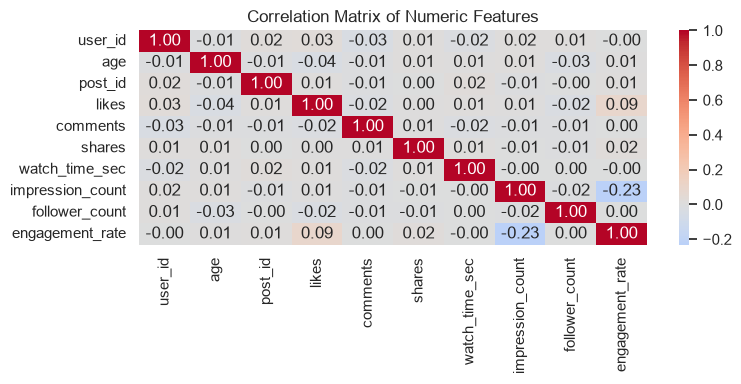

In [70]:
numeric_df = df.select_dtypes(include=np.number)
correlation_matrix = numeric_df.corr(numeric_only=True)
display(correlation_matrix.round(2))

plt.figure(figsize=(8, 4))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Matrix of Numeric Features")
plt.tight_layout()
plt.show()

### 3.3 Group-by summaries

In [10]:
print("Average likes, comments and shares by post type:")
display(df.groupby("post_type")[["likes", "comments", "shares"]].mean().round(2))

print("Average impressions by country (top 15):")
display(
    df.groupby("country")["impression_count"]
      .mean().sort_values(ascending=False).head(15).to_frame("average_impressions")
      .round(2)
)

print("Average engagement rate by post category:")
display(
    df.groupby("post_category")["engagement_rate"]
      .mean().sort_values(ascending=False).to_frame("average_engagement_rate")
      .round(4)
)

Average likes, comments and shares by post type:


,likes,comments,shares
post_type,,,
image,"10,104.870","1,525.240","1,019.290"
reel,"10,037.800","1,504.190",982.040
text,"10,100.150","1,499.110","1,013.990"
video,"10,188.600","1,479.160",996.830


Average impressions by country (top 15):


,average_impressions
country,
india,"52,462.390"
france,"51,727.670"
usa,"51,263.870"
uk,"51,119.390"
japan,"49,616.140"
brazil,"49,193.170"
uae,"48,928.410"
canada,"48,703.150"
germany,"48,605.410"


Average engagement rate by post category:


,average_engagement_rate
post_category,
food,1.359
tech,1.161
lifestyle,1.091
music,0.889
fitness,0.866
education,0.844
fashion,0.807
travel,0.702


## 4. Data wrangling 

### 4.1 Create additional fields


In [13]:
df["engagement_score"] = df[["likes", "comments", "shares"]].sum(axis=1)

for col in ["likes", "comments", "shares", "impression_count", "follower_count"]:
    df[f"log_{col}"] = np.log1p(df[col])

df["post_date"] = df["posted_at"].dt.date
df["post_hour"] = df["posted_at"].dt.hour  # dates without time information will have hour 0

display(df[[
    "likes", "comments", "shares", "engagement_score",
    "engagement_rate", "hashtag_count"
]].head())

,likes,comments,shares,engagement_score,engagement_rate,hashtag_count
0,"7,011.000",354.000,"1,157.000","8,522.000",0.191,3
1,"11,750.000","2,606.000","1,807.000","16,163.000",0.201,1
2,"4,862.000",344.000,955.000,"6,161.000",0.137,1
3,"5,350.000","1,083.000","1,049.000","7,482.000",0.106,3
4,"12,682.000","2,735.000","1,300.000","16,717.000",2.777,1


### 4.2 concatenation


In [11]:
split_point = len(df) // 2
df_part_a = df.iloc[:split_point].copy()
df_part_b = df.iloc[split_point:].copy()

df_recombined = pd.concat([df_part_a, df_part_b], axis=0)
print("Original cleaned rows:", len(df))
print("Rows after concatenation:", len(df_recombined))
print("Index/record count preserved:", len(df_recombined) == len(df))

Original cleaned rows: 5000
Rows after concatenation: 5000
Index/record count preserved: True


### 4.3 Group summaries by post type, country and sentiment

In [14]:
summary_by_type = df.groupby("post_type").agg(
    posts=("post_id", "count"),
    average_likes=("likes", "mean"),
    average_engagement_rate=("engagement_rate", "mean"),
    average_engagement_score=("engagement_score", "mean")
).sort_values("average_engagement_rate", ascending=False)

summary_by_country = df.groupby("country").agg(
    posts=("post_id", "count"),
    average_impressions=("impression_count", "mean"),
    average_engagement_rate=("engagement_rate", "mean")
).sort_values("average_engagement_rate", ascending=False)

summary_by_sentiment = df.groupby("sentiment").agg(
    posts=("post_id", "count"),
    average_likes=("likes", "mean"),
    average_engagement_rate=("engagement_rate", "mean"),
    average_watch_time=("watch_time_sec", "mean")
).sort_values("average_engagement_rate", ascending=False)

display(summary_by_type.round(3))
display(summary_by_country.round(3))
display(summary_by_sentiment.round(3))

,posts,average_likes,average_engagement_rate,average_engagement_score
post_type,,,,
video,1225,"10,188.600",1.122,"12,664.594"
text,1245,"10,100.148",1.065,"12,613.244"
image,1247,"10,104.865",0.896,"12,649.391"
reel,1283,"10,037.802",0.783,"12,524.032"


,posts,average_impressions,average_engagement_rate
country,,,
brazil,504,"49,193.175",1.541
australia,493,"48,346.383",1.324
france,496,"51,727.673",1.146
uae,503,"48,928.414",1.112
canada,513,"48,703.150",0.917
uk,493,"51,119.394",0.851
japan,472,"49,616.136",0.770
germany,490,"48,605.406",0.759
india,535,"52,462.387",0.655


,posts,average_likes,average_engagement_rate,average_watch_time
sentiment,,,,
negative,960,"10,208.097",1.038,"4,054.640"
neutral,1527,"9,923.194",0.991,"4,031.823"
positive,2363,"10,156.927",0.955,"3,980.731"


## 5. Statistical analysis

Calculate mean, median, mode, standard deviation, variance and percentiles for the required numeric measures.

In [73]:
stat_columns = [
    "likes", "comments", "shares", "watch_time_sec",
    "engagement_rate", "follower_count"
]

display(df[stat_columns].describe().round(3))


,likes,comments,shares,watch_time_sec,engagement_rate,follower_count
count,"4,850.000","4,850.000","4,850.000","5,000.000","5,000.000","5,000.000"
mean,"10,107.044","1,502.196","1,002.629","4,014.503",0.964,"393,698.225"
std,"5,789.819",869.538,579.615,"2,308.096",5.318,"230,927.885"
min,10.000,0.000,0.000,0.000,0.006,87.000
25%,"5,068.500",760.000,498.000,"2,017.750",0.146,"194,480.000"
50%,"10,105.500","1,497.000","1,012.000","4,034.500",0.254,"388,982.000"
75%,"15,115.000","2,256.000","1,501.000","6,020.250",0.505,"589,744.250"
max,"19,998.000","2,999.000","1,999.000","7,998.000",191.504,"799,533.000"


## 6. Data visualization

### 6.1 Matplotlib — Scatter: likes vs impressions

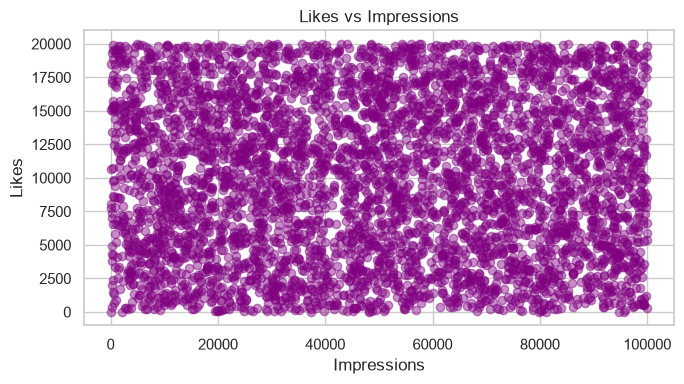

In [79]:
plt.figure(figsize=(7, 4))
plt.scatter(df["impression_count"], df["likes"], alpha=0.45, color="purple")
plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.title("Likes vs Impressions")
plt.tight_layout()
plt.show()

### 6.2 Matplotlib — Line: daily engagement trend

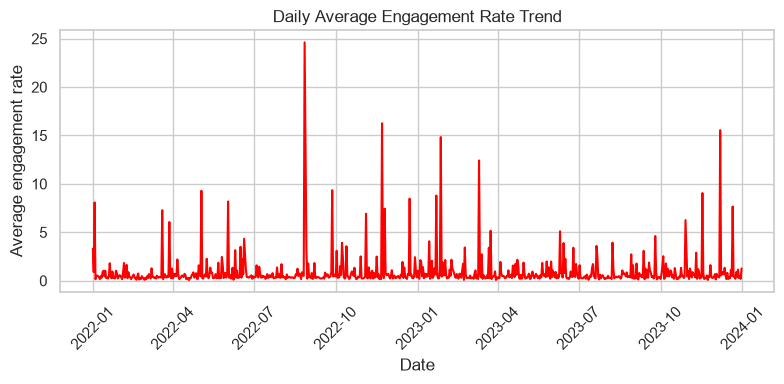

In [74]:
daily_engagement = (
    df.groupby(df["posted_at"].dt.date)["engagement_rate"]
      .mean().sort_index()
)
plt.figure(figsize=(8, 4))
plt.plot(pd.to_datetime(daily_engagement.index), daily_engagement.values,color="red")
plt.xlabel("Date")
plt.ylabel("Average engagement rate")
plt.title("Daily Average Engagement Rate Trend")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 6.3 Matplotlib — Bar: number of posts by category

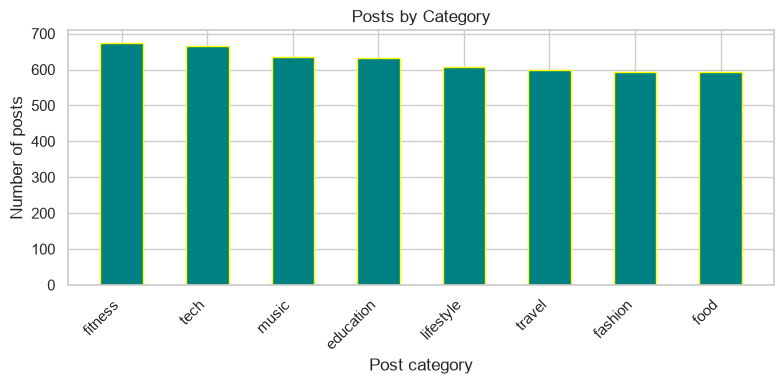

In [84]:
category_counts = df["post_category"].value_counts()

plt.figure(figsize=(8, 4))

plt.bar(
    category_counts.index.astype(str),
    category_counts.values,
    color="teal",
    edgecolor="yellow",
     width=0.5
)

plt.xlabel("Post category")
plt.ylabel("Number of posts")
plt.title("Posts by Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 6.4 Matplotlib — Pie: gender distribution

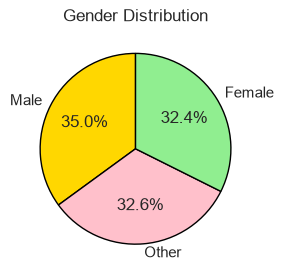

In [87]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(3, 3))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["gold", "pink", "lightgreen"],
    wedgeprops={"edgecolor": "black"}
)

plt.title("Gender Distribution")
plt.tight_layout()
plt.show()

### 6.5 Matplotlib — Histogram: age distribution

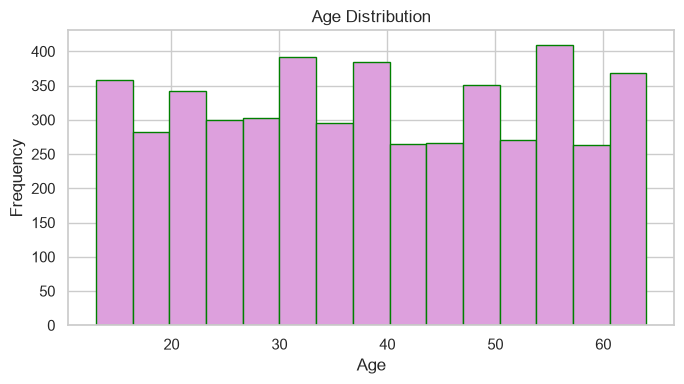

In [89]:
plt.figure(figsize=(7, 4))

plt.hist(
    df["age"],
    bins=15,
    color="plum",
    edgecolor="green"
)

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution")
plt.tight_layout()
plt.show()

### 6.6 Matplotlib — Box plot: engagement rate

C:\Users\ADMIN\AppData\Local\Temp\ipykernel_14716\3001720915.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


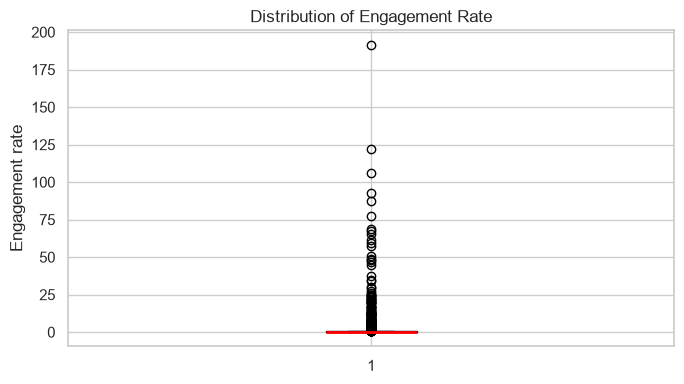

In [90]:
plt.figure(figsize=(7, 4))

plt.boxplot(
    df["engagement_rate"].dropna(),
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor="lightblue", edgecolor="black"),
    medianprops=dict(color="red", linewidth=2),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black")
)

plt.ylabel("Engagement rate")
plt.title("Distribution of Engagement Rate")
plt.tight_layout()
plt.show()

### 6.7 Seaborn — Count plot: post type

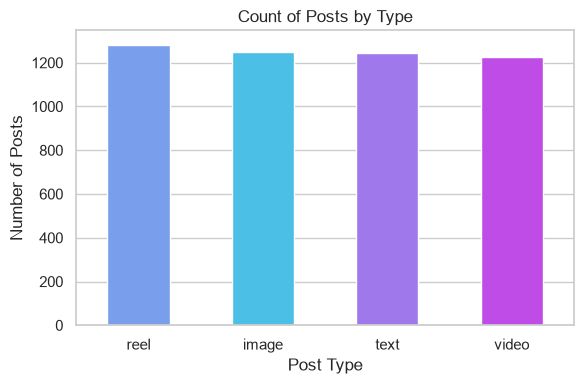

In [94]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=df,
    x="post_type",
    order=df["post_type"].value_counts().index,
    hue="post_type",
    palette="cool",
    legend=False,
    width=0.5
)

plt.xlabel("Post Type")
plt.ylabel("Number of Posts")
plt.title("Count of Posts by Type")
plt.tight_layout()
plt.show()

### 6.8 Seaborn — Bar plot: average likes by category

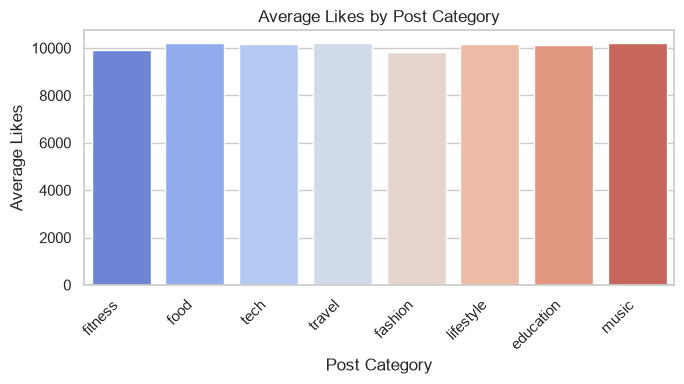

In [97]:
plt.figure(figsize=(7, 4))

sns.barplot(
    data=df,
    x="post_category",
    y="likes",
    estimator=np.mean,
    errorbar=None,
    hue="post_category",
    palette="coolwarm",
    legend=False
)

plt.xlabel("Post Category")
plt.ylabel("Average Likes")
plt.title("Average Likes by Post Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 6.9 Seaborn — Violin plot: followers by sentiment

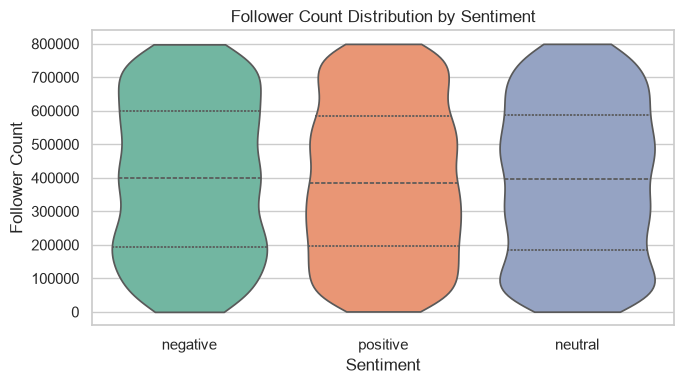

In [98]:
plt.figure(figsize=(7, 4))

sns.violinplot(
    data=df,
    x="sentiment",
    y="follower_count",
    inner="quartile",
    cut=0,
    hue="sentiment",
    palette="Set2",
    legend=False
)

plt.xlabel("Sentiment")
plt.ylabel("Follower Count")
plt.title("Follower Count Distribution by Sentiment")
plt.tight_layout()
plt.show()

### 6.10 Seaborn — Pair plot of numeric features

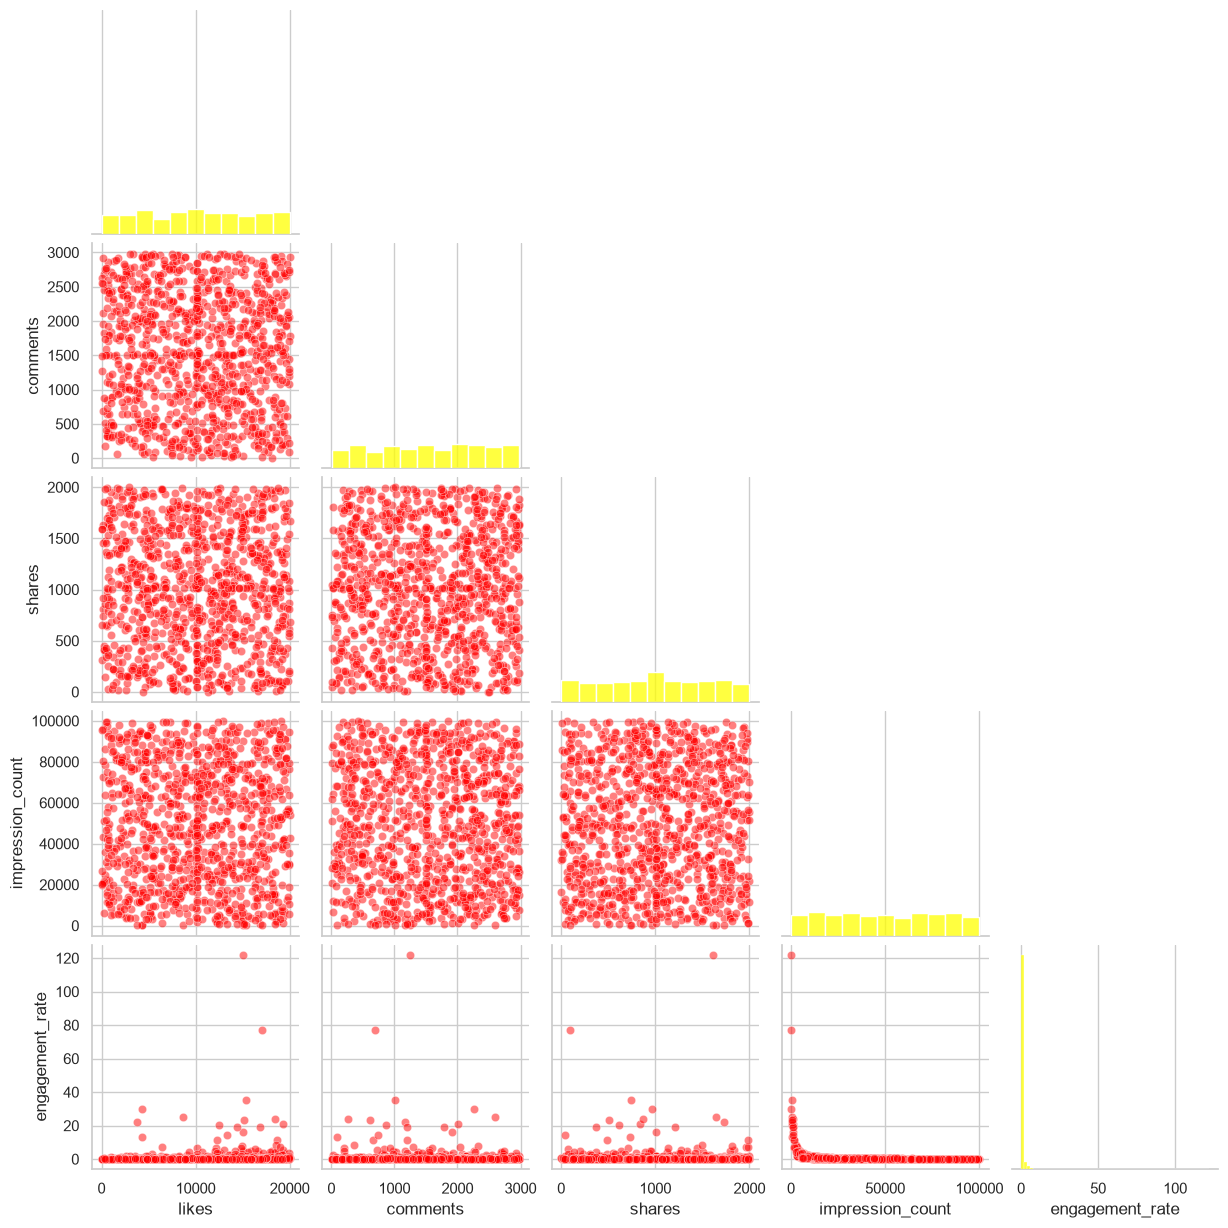

In [47]:
pair_columns = ["likes", "comments", "shares", "impression_count", "engagement_rate"]
pair_sample = df[pair_columns].dropna()
if len(pair_sample) > 1000:
    pair_sample = pair_sample.sample(1000, random_state=42)
sns.pairplot(pair_sample, corner=True, diag_kind="hist", diag_kws={"color": "yellow"}, plot_kws={"color": "red", "alpha": 0.5})
plt.show()

### 6.11 Seaborn — Heatmap of correlations

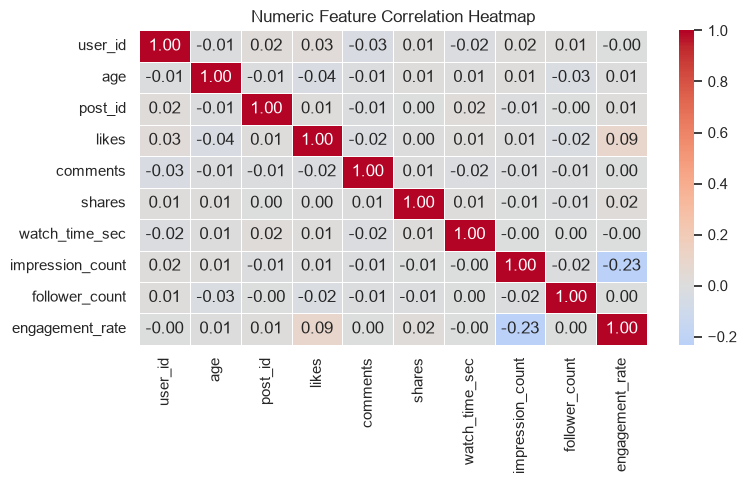

In [101]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Numeric Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### 6.12 Seaborn — Swarm plot: engagement by device

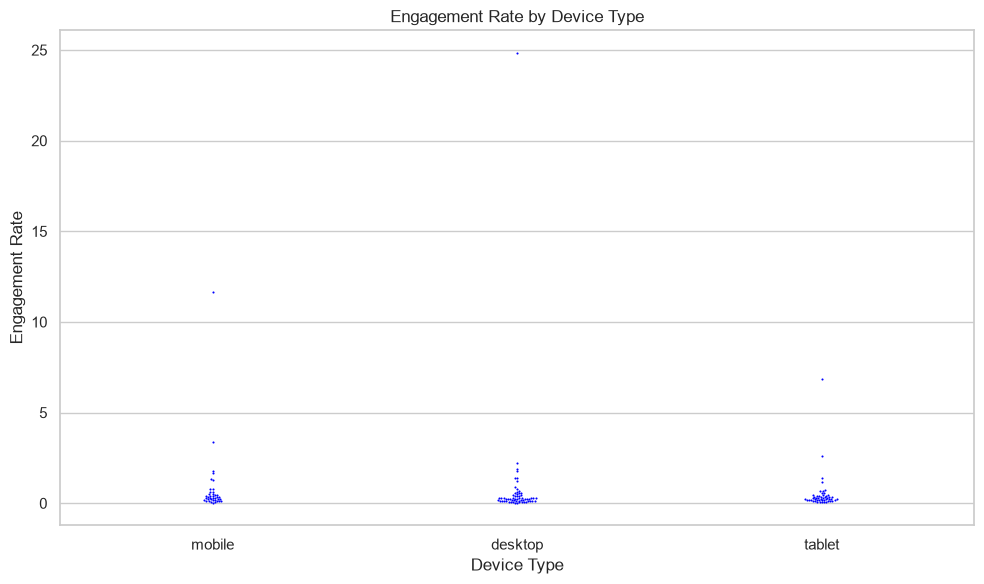

In [104]:
swarm_data = df[["device_type", "engagement_rate"]].dropna()

if len(swarm_data) > 150:
    swarm_data = swarm_data.sample(150, random_state=42)

plt.figure(figsize=(10, 6))

sns.swarmplot(
    data=swarm_data,
    x="device_type",
    y="engagement_rate",
    size=1.5,
    color="blue"
)

plt.xlabel("Device Type")
plt.ylabel("Engagement Rate")
plt.title("Engagement Rate by Device Type")
plt.tight_layout()
plt.show()

### 6.13 Plotly — Interactive chart

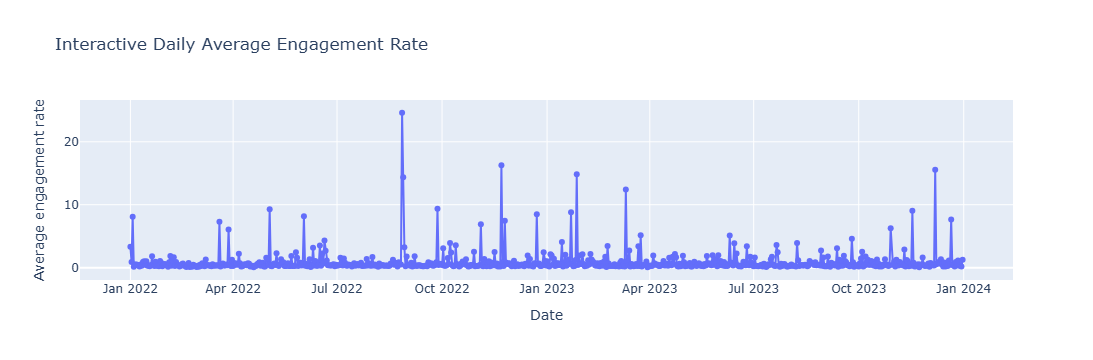

In [58]:
interactive_daily = (
    df.groupby(df["posted_at"].dt.date)
      .agg(average_engagement_rate=("engagement_rate", "mean"),
           average_impressions=("impression_count", "mean"))
      .reset_index()
)
interactive_daily["posted_at"] = pd.to_datetime(interactive_daily["posted_at"])

fig = px.line(
    interactive_daily,
    x="posted_at",
    y="average_engagement_rate",
    markers=True,
    title="Interactive Daily Average Engagement Rate"
)
fig.update_layout(xaxis_title="Date", yaxis_title="Average engagement rate")
fig.show()

## 7. Final insights and interpretation


In [59]:
# Content performance
best_post_type = df.groupby("post_type").agg(
    posts=("post_id", "count"),
    avg_engagement=("engagement_rate", "mean"),
    avg_likes=("likes", "mean")
).sort_values("avg_engagement", ascending=False)

best_category = df.groupby("post_category").agg(
    posts=("post_id", "count"),
    avg_engagement=("engagement_rate", "mean"),
    avg_likes=("likes", "mean")
).sort_values("avg_engagement", ascending=False)

best_country = df.groupby("country").agg(
    posts=("post_id", "count"),
    avg_engagement=("engagement_rate", "mean")
).sort_values("avg_engagement", ascending=False)

print("Post types ranked by average engagement:")
display(best_post_type.round(4))
print("Categories ranked by average engagement:")
display(best_category.round(4))
print("Countries ranked by average engagement rate:")
display(best_country.round(4))

Post types ranked by average engagement:


,posts,avg_engagement,avg_likes
post_type,,,
video,1225,1.122,"10,188.600"
text,1245,1.065,"10,100.148"
image,1247,0.896,"10,104.865"
reel,1283,0.783,"10,037.802"


Categories ranked by average engagement:


,posts,avg_engagement,avg_likes
post_category,,,
food,593,1.359,"10,225.523"
tech,665,1.161,"10,171.571"
lifestyle,607,1.091,"10,180.559"
music,635,0.889,"10,205.750"
fitness,675,0.866,"9,914.602"
education,631,0.844,"10,126.487"
fashion,594,0.807,"9,843.357"
travel,600,0.702,"10,196.304"


Countries ranked by average engagement rate:


,posts,avg_engagement
country,,
brazil,504,1.541
australia,493,1.324
france,496,1.146
uae,503,1.112
canada,513,0.917
uk,493,0.851
japan,472,0.770
germany,490,0.759
india,535,0.655


In [60]:
# User trends: age and verified account comparison
df["age_group"] = pd.cut(
    df["age"], bins=[12, 17, 24, 34, 44, 54, 64, 100],
    labels=["13–17", "18–24", "25–34", "35–44", "45–54", "55–64", "65+"]
)

age_engagement = df.groupby("age_group", observed=False).agg(
    posts=("post_id", "count"),
    avg_engagement=("engagement_rate", "mean"),
    avg_likes=("likes", "mean")
)
verified_comparison = df.groupby("is_verified").agg(
    posts=("post_id", "count"),
    avg_engagement=("engagement_rate", "mean"),
    avg_likes=("likes", "mean"),
    avg_impressions=("impression_count", "mean")
)

print("Engagement by age group:")
display(age_engagement.round(4))
print("Verified vs non-verified:")
display(verified_comparison.round(4))

Engagement by age group:


,posts,avg_engagement,avg_likes
age_group,,,
13–17,448,0.862,"10,616.746"
18–24,636,1.036,"10,029.097"
25–34,977,0.811,"10,367.392"
35–44,1096,0.956,"10,144.462"
45–54,916,1.205,"9,978.909"
55–64,927,0.899,"9,721.926"
65+,0,NaN,NaN


Verified vs non-verified:


,posts,avg_engagement,avg_likes,avg_impressions
is_verified,,,,
False,4517,0.955,"10,137.201","49,935.288"
True,483,1.054,"9,824.533","50,747.344"


In [61]:
# Behavioral insights: best time of day for impressions and device impact on watch time
# Note: if the source timestamp contains dates only, all records will have hour 0.
hourly_impressions = df.groupby("post_hour").agg(
    posts=("post_id", "count"),
    avg_impressions=("impression_count", "mean"),
    avg_engagement=("engagement_rate", "mean")
).sort_values("avg_impressions", ascending=False)

device_watch = df.groupby("device_type").agg(
    posts=("post_id", "count"),
    avg_watch_time=("watch_time_sec", "mean"),
    median_watch_time=("watch_time_sec", "median"),
    avg_engagement=("engagement_rate", "mean")
).sort_values("avg_watch_time", ascending=False)

print("Hours ranked by average impressions:")
display(hourly_impressions.round(3))
print("Watch time by device:")
display(device_watch.round(3))

Hours ranked by average impressions:


,posts,avg_impressions,avg_engagement
post_hour,,,
0,5000,"50,013.733",0.964


Watch time by device:


,posts,avg_watch_time,median_watch_time,avg_engagement
device_type,,,,
mobile,1684,"4,087.831","4,111.000",1.124
tablet,1658,"3,979.736","4,072.000",0.805
desktop,1658,"3,974.793","3,922.000",0.962


In [62]:
# Sentiment analysis
sentiment_results = df.groupby("sentiment").agg(
    posts=("post_id", "count"),
    avg_engagement=("engagement_rate", "mean"),
    avg_likes=("likes", "mean"),
    avg_comments=("comments", "mean"),
    avg_shares=("shares", "mean"),
    avg_watch_time=("watch_time_sec", "mean")
).sort_values("avg_engagement", ascending=False)

display(sentiment_results.round(4))

,posts,avg_engagement,avg_likes,avg_comments,avg_shares,avg_watch_time
sentiment,,,,,,
negative,960,1.038,"10,208.097","1,516.095","1,007.307","4,054.640"
neutral,1527,0.991,"9,923.194","1,528.404",996.565,"4,031.823"
positive,2363,0.955,"10,156.927","1,482.402","1,001.881","3,980.731"


### 7.1 Automatically generated findings to review
These statements are generated from the cleaned dataset. Confirm that they make sense alongside the tables and plots before including them in your report.

In [63]:
def top_group_text(series, metric_name):
    if series.empty:
        return f"No result available for {metric_name}."
    label = series.index[0]
    value = series.iloc[0]
    return f"Highest {metric_name}: {label} (average = {value:.4f})."

print(top_group_text(best_post_type["avg_engagement"], "engagement by post type"))
print(top_group_text(best_category["avg_engagement"], "engagement by category"))
print(top_group_text(best_country["avg_engagement"], "engagement rate by country"))
print(top_group_text(sentiment_results["avg_engagement"], "engagement by sentiment"))

best_age = age_engagement["avg_engagement"].dropna()
if not best_age.empty:
    print(top_group_text(best_age, "engagement by age group"))

best_hour = hourly_impressions["avg_impressions"].dropna()
if not best_hour.empty:
    print(top_group_text(best_hour, "impressions by hour"))

best_device = device_watch["avg_watch_time"].dropna()
if not best_device.empty:
    print(top_group_text(best_device, "watch time by device"))

Highest engagement by post type: video (average = 1.1224).
Highest engagement by category: food (average = 1.3586).
Highest engagement rate by country: brazil (average = 1.5407).
Highest engagement by sentiment: negative (average = 1.0385).
Highest engagement by age group: 13–17 (average = 0.8624).
Highest impressions by hour: 0 (average = 50013.7328).
Highest watch time by device: mobile (average = 4087.8308).


## 8. summary 

**Project:** Social Media Engagement Analytics Using Python

**Objective:** The purpose of this project is to analyze social media engagement metrics and identify patterns in content performance, audience behavior, posting trends and sentiment.

**Data preparation:** The CSV dataset was imported using Pandas. Data types were checked, the posting date was converted to datetime, missing values were handled, duplicate rows were removed, text categories were standardized, invalid numeric values were checked, and hashtag counts were extracted.

**Analysis performed:** Pandas and NumPy were used for dataset exploration, summary statistics, correlations, grouping and feature creation. The analysis calculated mean, median, mode, standard deviation, variance and percentiles for likes, comments, shares, watch time, engagement rate and follower count. An engagement score was created as the sum of likes, comments and shares.

**Visualizations:** The notebook includes Matplotlib and Seaborn charts such as scatter, line, bar, pie, histogram, box, count, violin, pair, heatmap and swarm plots, along with an interactive Plotly line chart.

**Key findings:** Complete this section after running the notebook. Use the generated tables and findings to state:
1. Which post type and category had the highest average engagement rate.
2. Which country had the highest average engagement rate.
3. How engagement differed across age groups and verified-account status.
4. Which posting hour had the highest average impressions (only meaningful if timestamps include time).
5. Which device type had the highest average watch time.
6. Which sentiment group had the highest average engagement.

**Conclusion:** The analysis provides a data-based view of social media performance.

